# 15 — Fusiones fijas: ¿combinar detectores mejora al mejor detector solo?

**Pregunta.** ¿Hay alguna combinación de detectores no supervisados que, medida con **la misma vara que los
individuales** y con la **selección controlada**, mejore al mejor detector solo? Este notebook responde para las
**fusiones fijas** (reglas sin parámetros aprendidos); la fusión online va en el
[notebook 16](16_fusion_online.ipynb). Todo está pre-registrado en el
[ADR-011](../../docs/decisions/ADR-011-preregistro-fusiones.md), congelado antes de programar y calcular.

**Qué hace y qué no.** Solo lee `results/fusion/fijas/` (lo escribe `python -m regimenes.fusion.fijas ejecutar`,
un solo proceso) y los resultados versionados de las fusiones anteriores, y dibuja. Las tablas y figuras están en
`regimenes.fusion.figuras_fijas`. **Todas las cifras salen de celdas.**

**Cómo leerlo en 30 segundos:** la figura y las conclusiones de la sección 0.

In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.precision', 3)

from regimenes.fusion import figuras_fijas as ff

D = ff.cargar()                                   # results/fusion/fijas/ (criterio, evaluación, MCS-F, lecturas)
CRIT, EV, ELEC, CAT = D['criterio'], D['evaluacion'], D['eleccion'], D['catalogo']
print(f"Veredicto: {CRIT['veredicto'].iloc[0]}  ·  señales evaluadas: {EV['id'].nunique()} ids × 3 tramos")

Veredicto: no aporta: combinar no mejora al mejor detector solo  ·  señales evaluadas: 853 ids × 3 tramos


## 0. Resumen

Cada punto es una señal en todo el periodo fuera de muestra (OOS), situada por su **score de detección** (F1 entre
la precisión diaria y el recall por evento, la vara de los individuales). Una fila por familia de fusión; la
primera fila son los detectores solos (color = familia de detectores, como en el notebook 14). La **línea
punteada** es el mejor detector solo (I\*); la **estrella** es la fusión elegida sin mirar el resultado (F\*,
elegida en la primera mitad); el **rombo** es la que se elegiría mirando todo el OOS. A la derecha, cuántas fusiones
de cada fila superan a I\*.

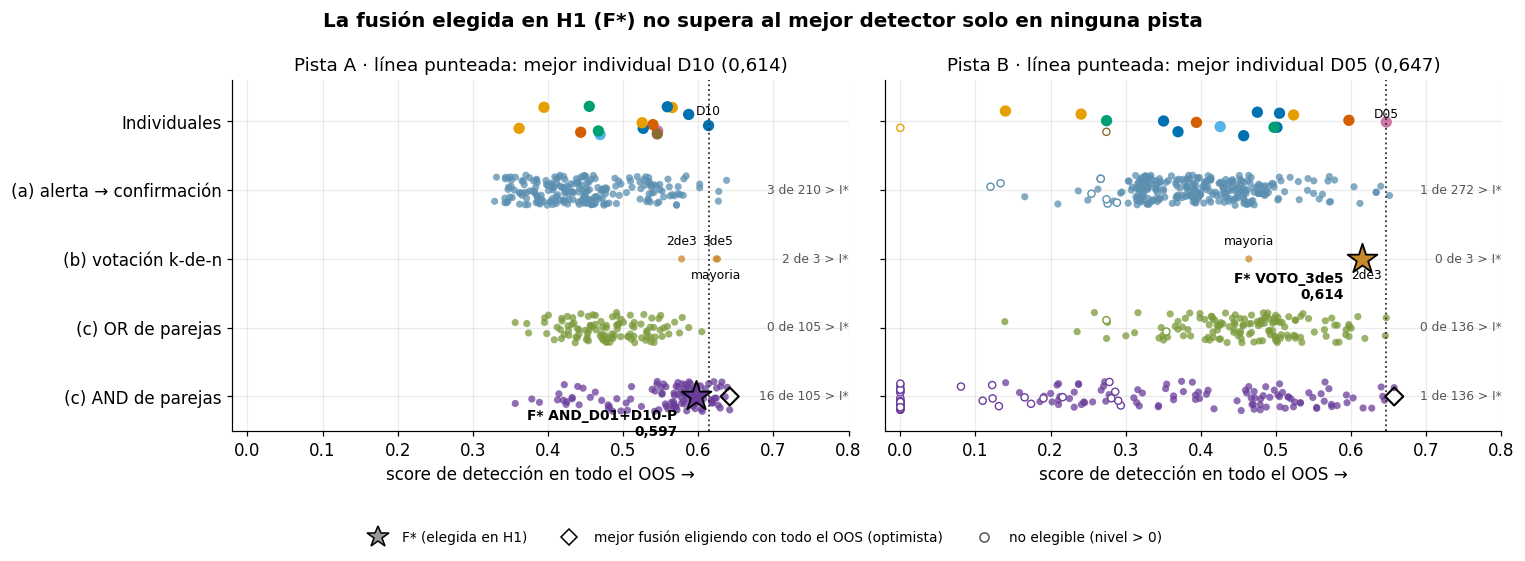

In [2]:
fig = ff.figura_resumen(EV, CRIT, D['optimismo'])
plt.show()

In [3]:
ANT_VARA = ff.tabla_antecedentes_vara(EV, CRIT)
HECHOS = ff.hechos(D, ANT_VARA)
display(Markdown('\n'.join(f'{i}. {c}' for i, c in enumerate(ff.conclusiones(HECHOS), 1))))

1. **Veredicto (ADR-011 §6.1): «no aporta: combinar no mejora al mejor detector solo».** El criterio exige (i), (ii) y (iii) en las dos pistas: (i) falla en A y B; (ii) falla en A.
2. **Pista A:** F\* = `AND_D01+D10-P` puntúa 0,597 en todo el OOS frente a 0,614 de D10 (i ✗); queda fuera del MCS-F (p = 0,063; (ii) ✗) y en H2 gana a I\*_H1 = D10-P (0,541 frente a 0,471; (iii) ✓).
3. **Pista B:** F\* = `VOTO_3de5` puntúa 0,614 en todo el OOS frente a 0,647 de D05 (i ✗); queda dentro del MCS-F (p = 0,412; (ii) ✓) y en H2 gana a I\*_H1 = D01 (0,543 frente a 0,428; (iii) ✓).
4. **Haberlas, las hay, pero no se pueden elegir de antemano.** Con todo el OOS, 21 de 423 fusiones superan a D10 en A y 2 de 547 a D05 en B. Eligiendo con todo el OOS se ganaría 0,045 (A) y 0,043 (B) de score: ese es el optimismo de la selección.
5. **El orden de H1 apenas predice el de H2:** correlación de Spearman entre el score de las fusiones en las dos mitades de 0,36 en A y 0,45 en B. (iii) se cumple porque I\*_H1 también se hunde en H2, no porque F\* sea mejor que el mejor detector: en H2, D10 puntúa 0,706 (F\* 0,541) en A y D05 0,619 (F\* 0,543) en B.
6. **La votación por mayoría, que no elige a nadie**, puntúa 0,624 en A (por encima de D10) y 0,464 en B (por debajo de D05): no se sostiene en las dos pistas. Es la referencia V de la fusión online (notebook 17).

## 1. Antecedentes (sin peso en el veredicto)

Antes de este notebook había dos fusiones, cada una en su notebook (hoy unificados aquí):

- **D7 alerta + D8 confirma** (antiguo notebook 15): D7 (CUSUM online) abre *vigilancia* y D8 (HMM t-Student)
  *confirma* con `p_crisis ≥ 0,50` tres sesiones seguidas; el aviso vale 63 sesiones. Máquina causal
  `regimenes.fusion.maquina`. Conclusión de entonces: **mejora a D8 solo pero no a D7 solo**, y los avisos casi
  nunca anticipan el inicio de una crisis.
- **D2 alerta + D6 confirma** (antiguo notebook 16): D6 (GJR-GARCH-t) fijo como confirmador y cribado de las otras
  11 alertas. Conclusión de entonces: **D2+D6 mejora a sus dos sensores, pero por poco**; D2 y D7 quedaban
  empatados como alerta y ningún aviso anticipaba una crisis.

Ambas se medían con la **utilidad operativa** (`cobertura − falsas alarmas − trampas − 5 × cambios`), no con la vara
del ranking, y frente a **sus propios sensores**, no frente al mejor detector. Sus resultados siguen versionados
en `results/fusion/d07_d08/` y `results/fusion/d02_d06/`; aquí solo se leen.

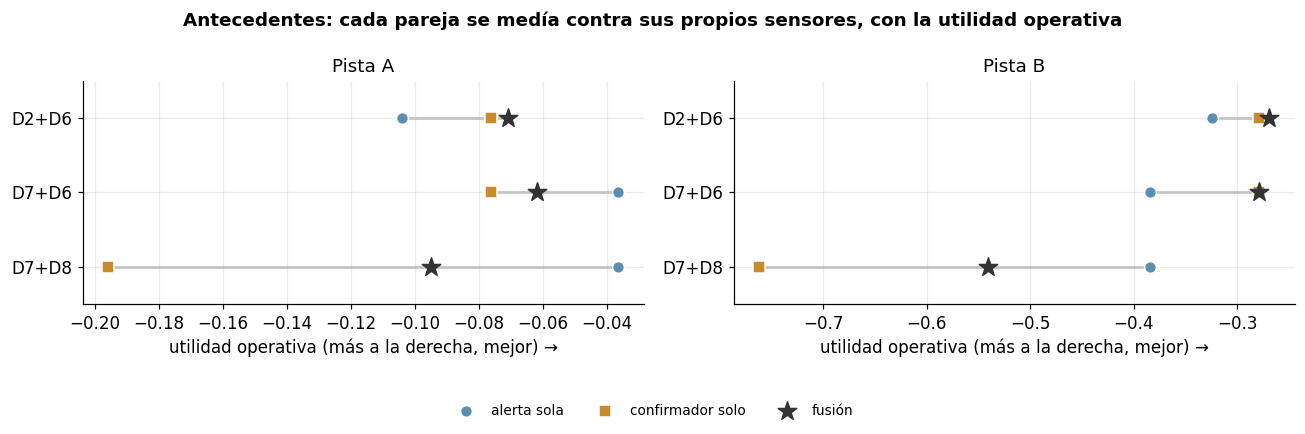

alerta_sola  confirmador_solo  fusion                          veredicto  mejora_a_los_dos  avisos  avisos_que_anticipan
pista pareja                                                                                                                          
A     D2+D6        -0.104            -0.076  -0.071                       mejora_ambos              True     2.0                   0.0
      D7+D6        -0.037            -0.076  -0.062  mejora_confirmador_pero_no_alerta             False     NaN                   NaN
      D7+D8        -0.037            -0.196  -0.095  mejora_confirmador_pero_no_alerta             False     6.0                   1.0
B     D2+D6        -0.324            -0.279  -0.269                       mejora_ambos              True     6.0                   0.0
      D7+D6        -0.385            -0.279  -0.279  mejora_alerta_pero_no_confirmador             False     NaN                   NaN
      D7+D8        -0.385            -0.762  -0.540  mejora_confirmador_pero_no_alerta             False     5.0                   0.0

In [4]:
ANT = ff.tabla_antecedentes()
fig = ff.figura_antecedentes(ANT)
plt.show()
display(ANT.set_index(['pista', 'pareja']).round(3))

**El antiguo notebook 16 (D2+D6) ya vio el problema de elegir a mano.** Su control por mitades elegía la alerta en la primera
mitad y miraba su puesto en la segunda: la ganadora cambiaba, y D2 no ganaba en ninguna mitad.

In [5]:
display(ff.tabla_mitad_antigua().set_index('ambito'))

,elegida_en_1a_mitad,su_puesto_en_2a,puesto_D02_1a,puesto_D02_2a
ambito,,,,
pista A,D12,6 de 6,5 de 6,3 de 6
pista B,D05,1 de 7,5 de 7,4 de 7
media A+B,D05,2 de 6,4 de 6,3 de 6


**Las parejas antiguas, con la vara nueva.** Las tres son parejas de la familia (a) de este ADR (misma máquina y
configuración, con el confirmador binarizado), así que se pueden poner en el ranking de las fusiones de todo el OOS:

In [6]:
display(ANT_VARA.set_index(['pista', 'pareja']).round(3))

id  score_oos      puesto mejor_individual  diferencia
pista pareja                                                                 
A     D7+D8   PAR_D07>D08      0.477  206 de 423        D10 0,614      -0.137
      D7+D6   PAR_D07>D06      0.534  132 de 423        D10 0,614      -0.079
      D2+D6   PAR_D02>D06      0.533  136 de 423        D10 0,614      -0.081
B     D7+D8   PAR_D07>D08      0.367  362 de 547        D05 0,647      -0.280
      D7+D6   PAR_D07>D06      0.571   38 de 547        D05 0,647      -0.076
      D2+D6   PAR_D02>D06      0.569   41 de 547        D05 0,647      -0.078

**Por qué se amplía.** (1) Las dos parejas se eligieron **después de ver el benchmark**: es un sesgo de selección.
(2) La utilidad operativa no es la vara de los individuales, así que no responde a «¿mejora al mejor detector?».
(3) Si en vez de dos parejas se prueban **cientos de combinaciones**, alguna ganará por azar: hace falta controlar
la multiplicidad, eligiendo en una mitad y evaluando en la otra, y exigir el MCS. Eso es el ADR-011.

## 2. Diseño (resumen del ADR-011)

| pieza | qué se fija ([ADR-011](../../docs/decisions/ADR-011-preregistro-fusiones.md)) |
|---|---|
| **Candidatos** (§2) | todos los no supervisados con panel OOS: D01–D12 + D15-U, D10-P, D18-P (15 en A); más D10-R y D14-R (17 en B). Sin D16 ni D17 |
| **Señal** (§2.1) | la binaria de cada candidato, `state == n_states − 1` (la que puntúa el ranking) |
| **(a) alerta → confirmación** (§3.1) | todos los pares **ordenados** X→Y con la máquina de los notebooks antiguos (0,50 / 3 / 63); crisis = vigilancia ∪ confirmado («accionable») |
| **(b) votación k-de-n** (§3.2) | 2 de 3 y 3 de 5 con el top del orden de **H1**; mayoría de todos (8 de 15 / 9 de 17) |
| **(c) OR y AND** (§3.3) | cada pareja no ordenada, día a día |
| **Vara** (§5.1) | `score_deteccion` y nivel del ranking; MCS al 10 % con los 5 baselines, bloque fijo 66 (A) / 50 (B) |
| **Mitades** (§5.2) | corte en ⌊n/2⌋ sesiones OOS: **F\*** = la primera de **todas** las fusiones en el orden de H1 (con nivel 0); se evalúa en H2 |
| **Criterio** (§6.1) | aporta si en **las dos pistas** F\*: (i) supera en todo el OOS al mejor individual (D10 0,614 en A; D05 0,647 en B), (ii) entra en el MCS-F y (iii) en H2 supera a I\*_H1 |

In [7]:
display(ff.tabla_recuento(CAT))

pista,A,B
individuales (candidatos),15,17
(a) parejas alerta→confirmación,210,272
(b) votación k-de-n,3,3
(c) OR y AND de parejas,210,272
sensibilidad (a) «tras aviso» (sin peso),210,272
referencia «confirmado» puro (sin peso),15,17
total principal (entra en la selección de F*),423,547


desde       hasta  sesiones  crisis
pista mitad                                                    
A     H1 (selección)   1970-05-12  1998-04-24      7066       5
      H2 (evaluación)  1998-04-27  2026-05-29      7067      12
B     H1 (selección)   2010-04-12  2018-05-01      2029       4
      H2 (evaluación)  2018-05-02  2026-05-29      2030       5

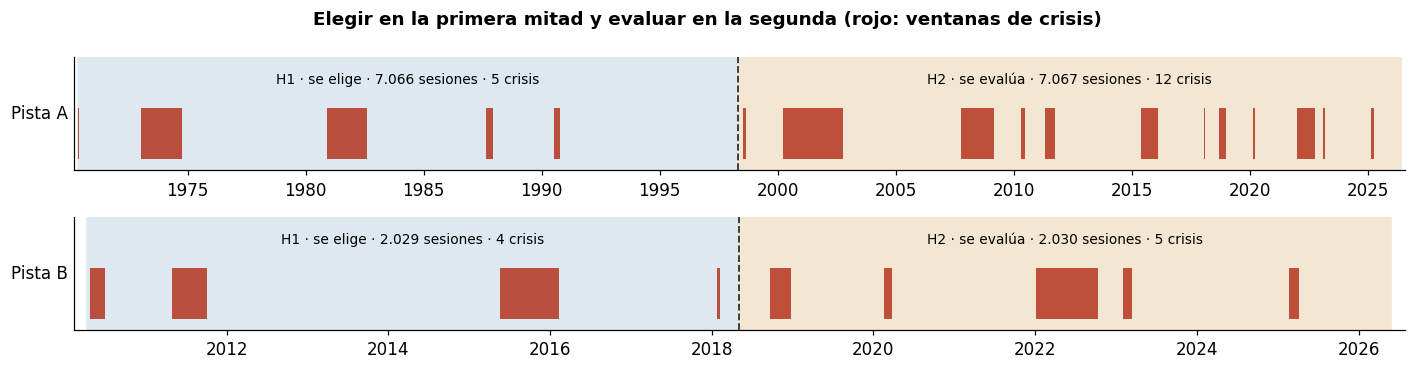

In [8]:
display(pd.concat([ff.tramos_pista(p) for p in ff.PISTAS]).set_index(['pista', 'mitad']))
fig = ff.figura_mitades()
plt.show()

H1 de B tiene solo 4 crisis (una de 10 días): el recall por evento salta de 0,25 en 0,25 y la selección en B es
ruidosa. Está declarado en el ADR y no se cambia el corte.

## 3. Resultados por familia

**Parejas (a) y (c).** Cada casilla es una pareja; el color es su score en todo el OOS **menos** el del mejor
detector solo: rojo (con «+») lo supera, azul no llega, gris no es elegible. La diagonal (recuadrada) son los
propios detectores. En (a), filas = quien avisa y columnas = quien confirma; en (c), encima de la diagonal el OR y
debajo el AND.

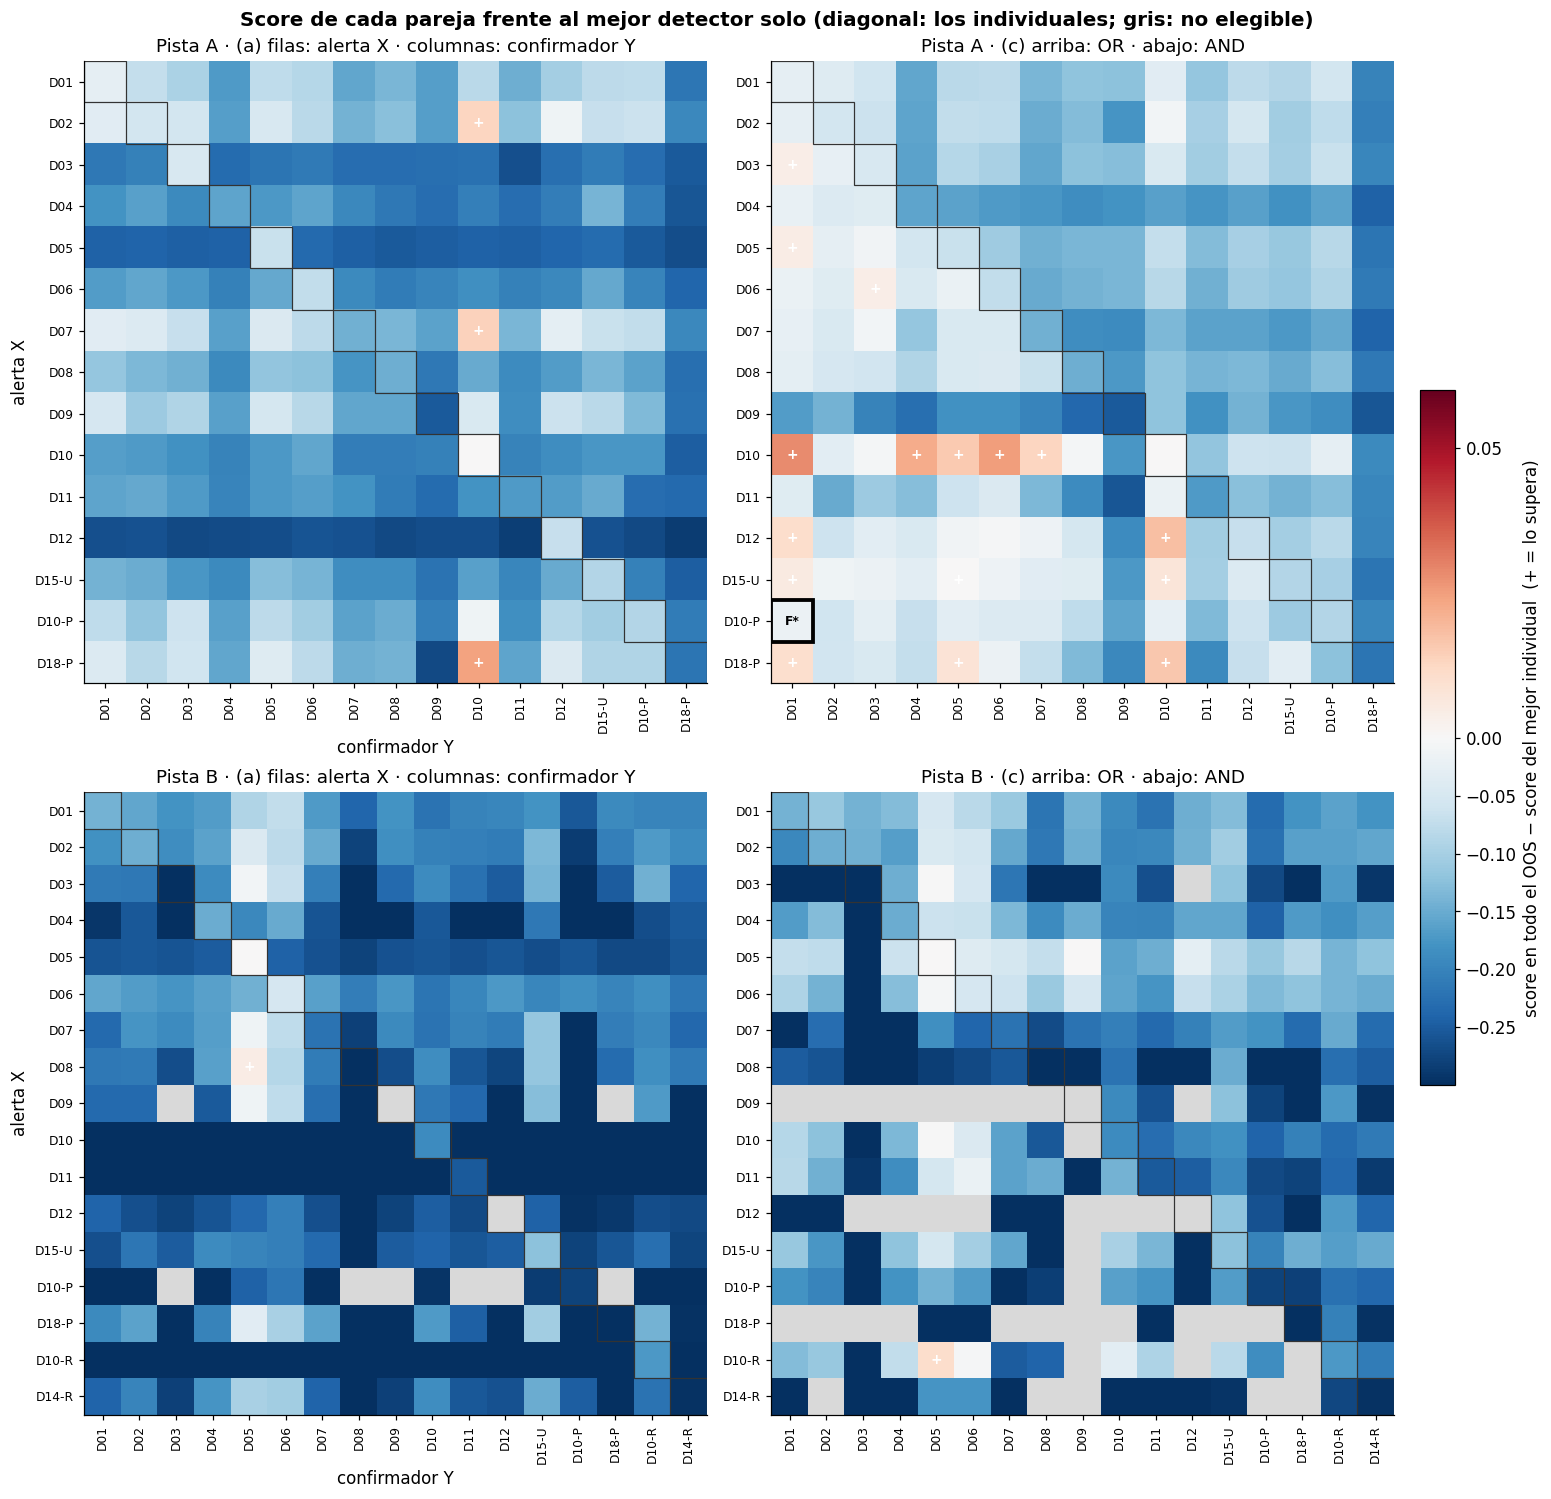

In [9]:
fig = ff.figura_mapas(EV, CAT, CRIT)
plt.show()

**En (a) pesa tanto quien avisa como quien confirma.** La propiedad que anticipaba el ADR (cuanto más marca Y, más
se parece la pareja a Y con persistencia) solo se nota en las columnas de los confirmadores que más marcan. En el
resto, cada aviso de X abre 63 sesiones de vigilancia que cuentan como crisis: la pareja nunca marca menos días que
su confirmador solo (sube el recall y, sobre todo en A, baja la precisión), y por eso hay filas casi de un solo
color, las de las alertas que avisan a menudo. Las pocas casillas rojas de (a) están en la columna del mejor
detector (D10 en A, D05 en B). En (c), las que superan al mejor son casi todas
AND con D10, D01 o D05 (en A) y con D05 (en B): recortan días falsos de un buen detector a costa de algo de recall.

**Votaciones (b).**

In [10]:
display(ff.tabla_votaciones(EV, ELEC, CRIT).set_index(['pista', 'votación']).round(3))

miembros  score_H1  score_H2  score_oos  supera_I*_oos
pista votación                                                                                 
A     VOTO_2de3                 D10-P · D02 · D10     0.613     0.561      0.578          False
      VOTO_3de5     D10-P · D02 · D10 · D01 · D03     0.603     0.646      0.626           True
      VOTO_mayoria              los 15 candidatos     0.554     0.681      0.624           True
B     VOTO_2de3                   D01 · D05 · D06     0.732     0.571      0.621          False
      VOTO_3de5     D01 · D05 · D06 · D07 · D10-R     0.864     0.543      0.614          False
      VOTO_mayoria              los 17 candidatos     0.400     0.520      0.464          False

**Ganador de cada familia en H1** y su puesto en H2 (entre las 423/547 y dentro de su familia):

In [11]:
display(ff.tabla_ganadores(D['ganadores']).set_index(['pista', 'familia']).round(3))

ganador_H1  puesto_H1  score_H1  score_H2  puesto_H2  puesto_H2_familia  score_oos
pista familia                                                                                                
A     (a) alerta→conf.  PAR_D07>D10-P         14     0.630     0.493        311                138      0.541
      (b) votación          VOTO_2de3         23     0.613     0.561        202                  3      0.578
      (c) OR/AND        AND_D01+D10-P          1     0.711     0.541        232                144      0.597
B     (a) alerta→conf.  PAR_D18-P>D07          6     0.819     0.339        358                173      0.486
      (b) votación          VOTO_3de5          1     0.864     0.543         56                  2      0.614
      (c) OR/AND        AND_D05+D10-R          2     0.863     0.601         11                 10      0.657

## 4. Selección en H1 y evaluación en H2

Cada punto es una fusión (o un detector, cuadrados): en el eje x su score en H1, donde se elige; en el y, en H2,
donde se evalúa. Si elegir en H1 sirviera, los puntos irían por la diagonal. La línea punteada es la vara del
criterio (iii): el score en H2 del mejor detector de H1.

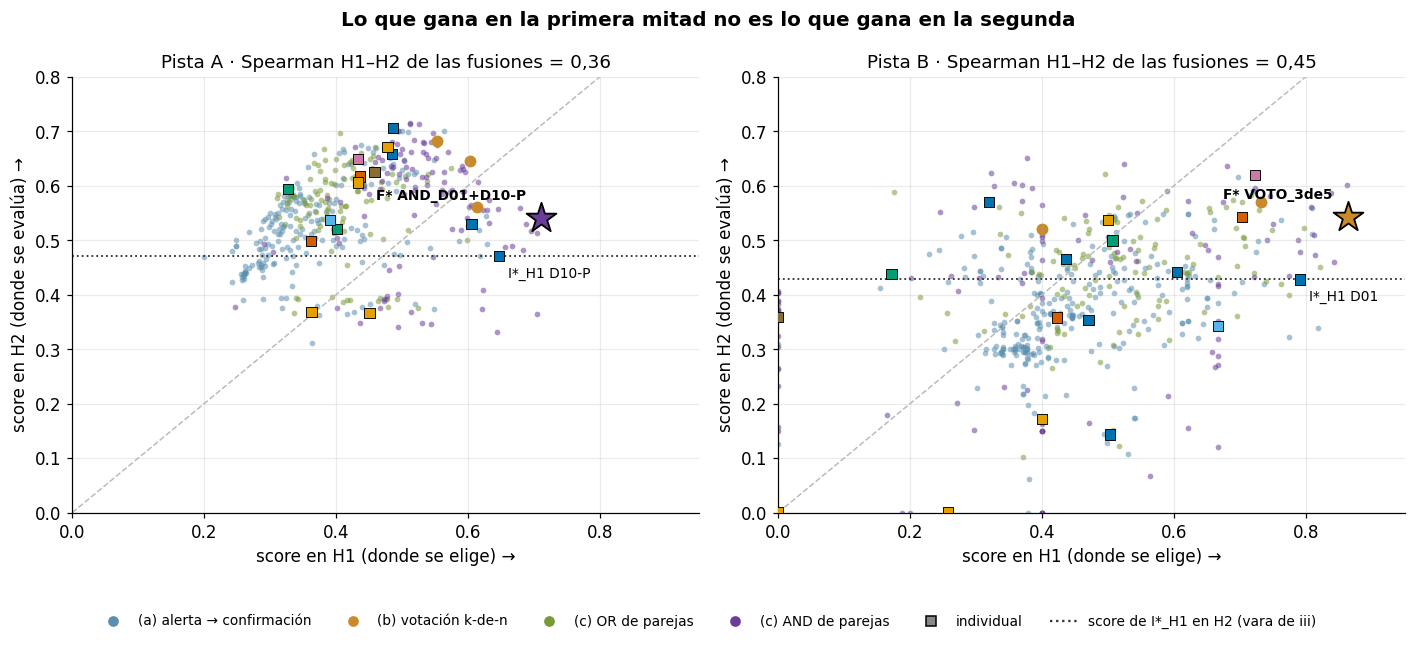

In [12]:
fig = ff.figura_h1_h2(EV, CRIT)
plt.show()

**Cuánto vale cada elección.** Para cada papel, su score en todo el OOS (lleno) y solo en H2 (hueco). La
«mejor fusión optimista» es la que se elegiría mirando todo el OOS: la diferencia con F\* es el **optimismo** de
seleccionar con las mismas crisis con que se puntúa.

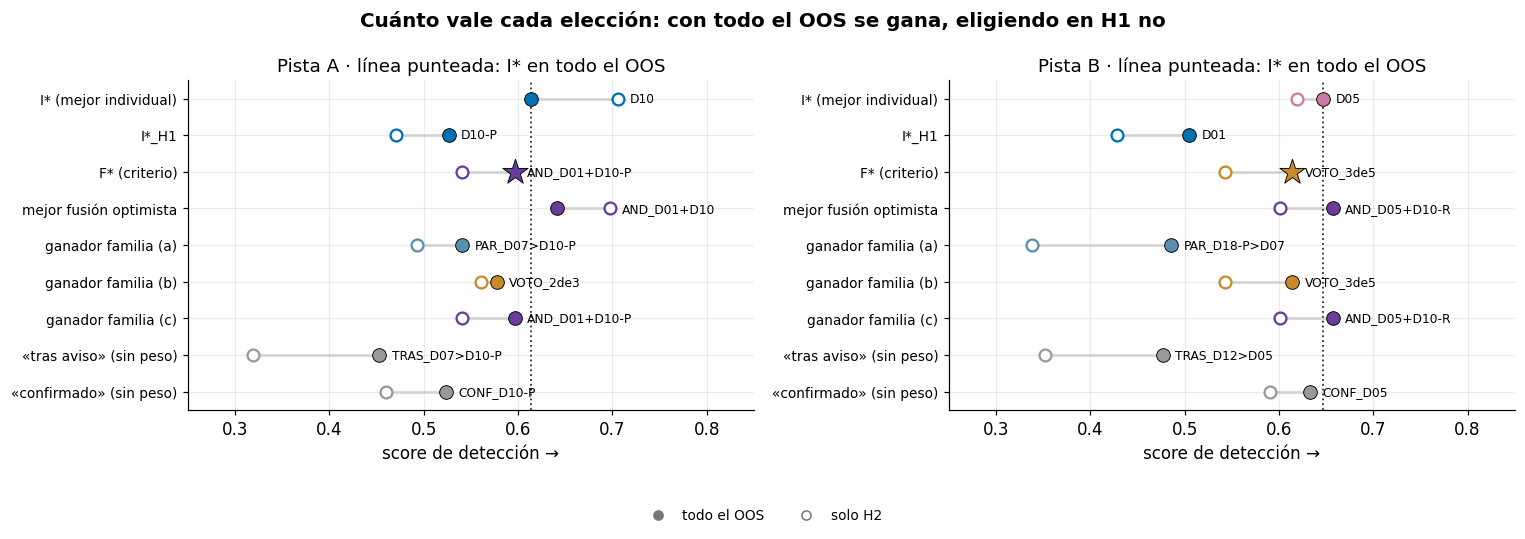

,mejor_oos,score_mejor_oos,f_star,score_f_star_oos,optimismo
pista,,,,,
A,AND_D01+D10,0.642,AND_D01+D10-P,0.597,0.045
B,AND_D05+D10-R,0.657,VOTO_3de5,0.614,0.043


In [13]:
SEL = ff.tabla_seleccion(D)
fig = ff.figura_seleccion(SEL)
plt.show()
display(D['optimismo'].set_index('pista').round(3))

## 5. Criterio del §6.1 y MCS-F

Comparaciones de score sin redondear y estrictas; (ii) se lee en el MCS de todo el OOS (como los individuales).

In [14]:
display(ff.tabla_criterio(CRIT))
display(Markdown(f"**Veredicto: «{CRIT['veredicto'].iloc[0]}».**"))

F*     frente a cumple
pista condición                                                                                     
A     (i) nivel 0 y score OOS > mejor individual   AND_D01+D10-P 0,597 (nivel 0)    D10 0,614      ✗
      (ii) dentro del MCS-F al 10 % (todo el OOS)                          fuera        MCS-F      ✗
      (iii) en H2: nivel 0 y score > I*_H1                       0,541 (nivel 0)  D10-P 0,471      ✓
      **pista**                                                                                    ✗
B     (i) nivel 0 y score OOS > mejor individual       VOTO_3de5 0,614 (nivel 0)    D05 0,647      ✗
      (ii) dentro del MCS-F al 10 % (todo el OOS)                         dentro        MCS-F      ✓
      (iii) en H2: nivel 0 y score > I*_H1                       0,543 (nivel 0)    D01 0,428      ✓
      **pista**                                                                                    ✗

**Veredicto: «no aporta: combinar no mejora al mejor detector solo».**

**MCS-F al 10 %** (todo el OOS): los individuales, los 5 baselines y F\*. La barra es la pérdida media 1 − J de
Youden con crisis equiponderadas (menos es mejor); opaca si queda dentro del conjunto, clara si sale, con el
p-valor del MCS al lado.

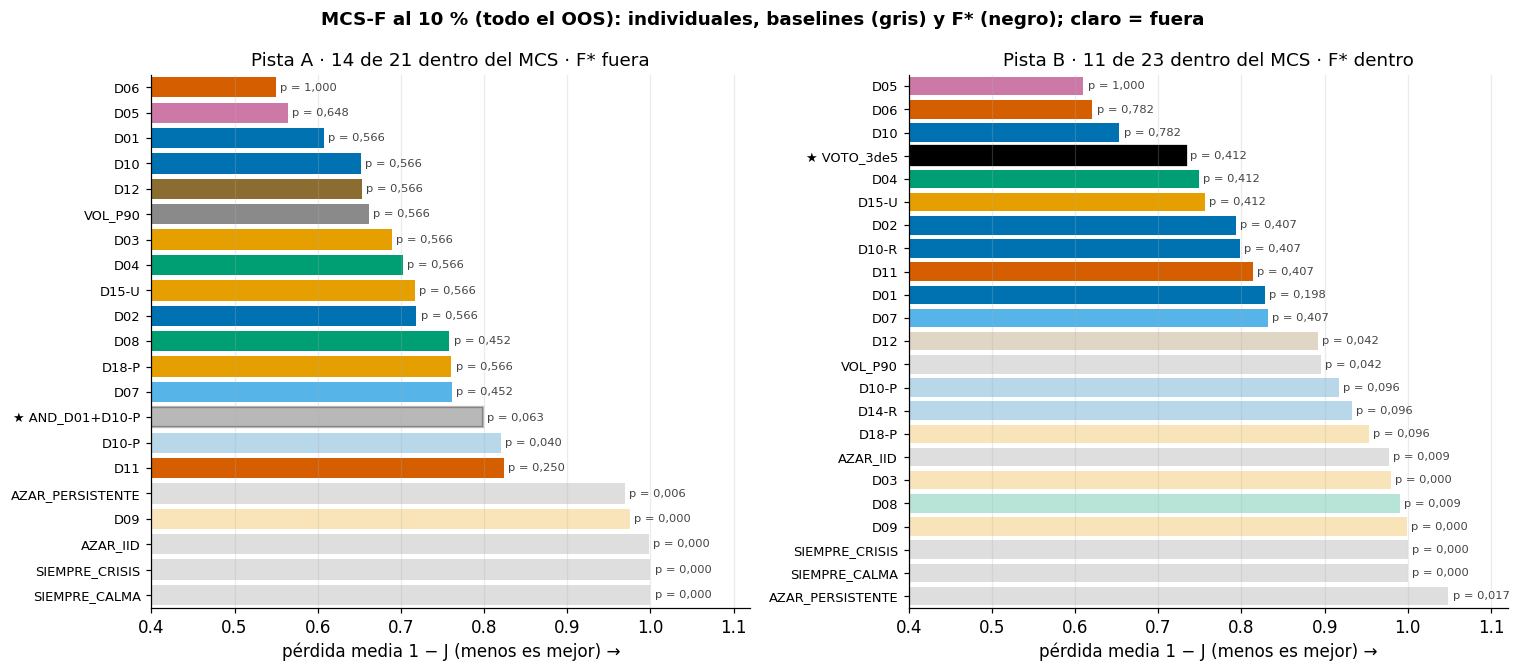

In [15]:
fig = ff.figura_mcs(D['mcs'], CRIT)
plt.show()

**MCS-F solo en H2** (sin peso, §6.3): 12 crisis en A y solo 5 en B.

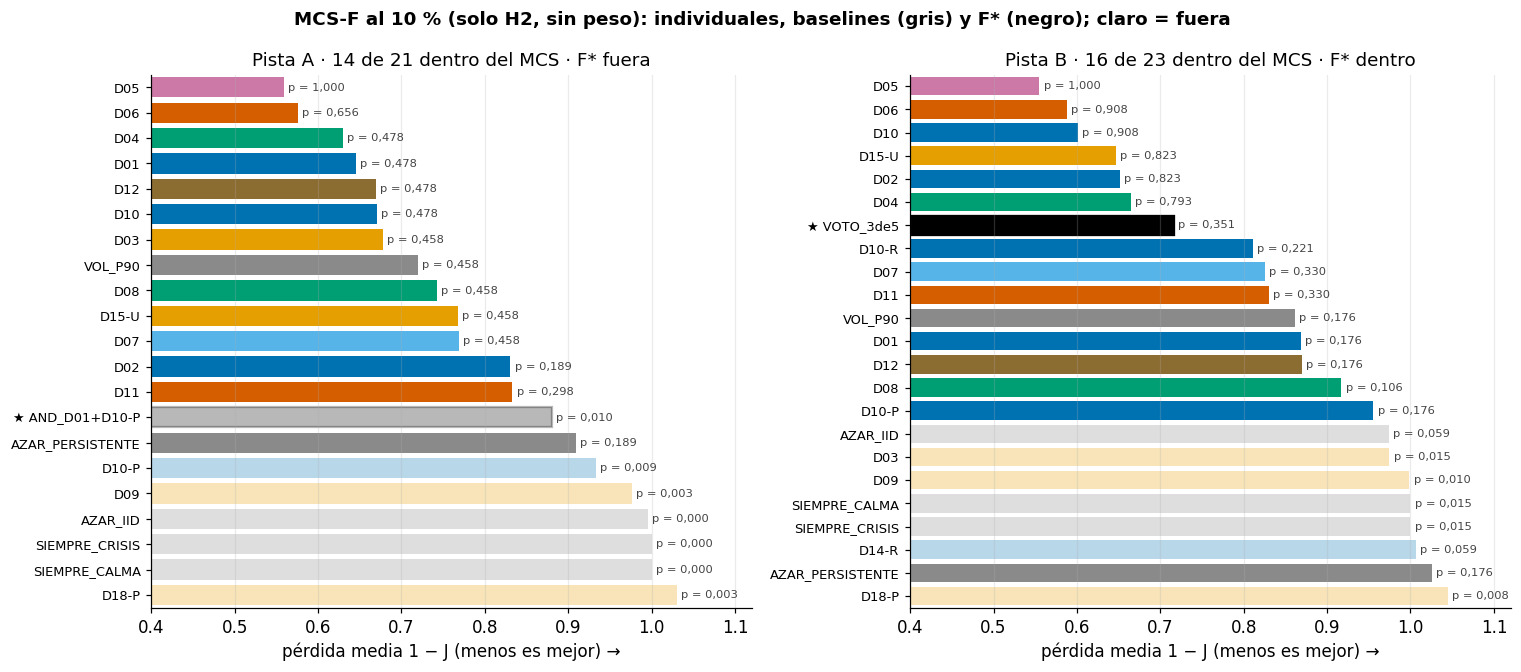

In [16]:
fig = ff.figura_mcs(D['mcs_H2'], CRIT, 'solo H2, sin peso')
plt.show()

## 6. Lecturas sin peso (§6.3)

**Variantes de (a).** «Confirmación tras aviso» exige que cada confirmación de Y venga precedida de un aviso de X
(la lectura secuencial estricta); «confirmado» puro es cada detector con persistencia 3.

In [17]:
display(ff.tabla_variantes(D['variantes']).round(3))

id  score_H1  nivel_H2  score_H2  score_oos  nivel_oos
pista grupo             lectura                                                                                    
A     «tras aviso»      elegida en H1            TRAS_D07>D10-P     0.689       0.0     0.319      0.453          0
                        elegida con todo el OOS    TRAS_D05>D12       NaN       NaN       NaN      0.655          0
      «confirmado» puro elegida en H1                CONF_D10-P     0.666       0.0     0.460      0.524          0
                        elegida con todo el OOS        CONF_D10       NaN       NaN       NaN      0.618          0
B     «tras aviso»      elegida en H1              TRAS_D12>D05     0.757       0.0     0.351      0.477          0
                        elegida con todo el OOS    TRAS_D11>D05       NaN       NaN       NaN      0.622          0
      «confirmado» puro elegida en H1                  CONF_D05     0.720       0.0     0.591      0.633          0
                        elegida con todo el OOS        CONF_D05       NaN       NaN       NaN      0.633          0

**Utilidad operativa** (la vara de los notebooks antiguos) de F\*, la votación por mayoría (V), I\* e I\*_H1, en
todo el OOS y en H2:

In [18]:
display(ff.tabla_utilidad(D['utilidad']).round(3))

cobertura  falsas_alarmas  cambios  utilidad
pista tramo papel id                                                         
A     oos   F*    AND_D01+D10-P      0.249           0.395    0.011    -0.202
            V     VOTO_mayoria       0.645           0.534    0.036    -0.071
            I*    D10                0.481           0.545    0.042    -0.273
            I*_H1 D10-P              0.276           0.523    0.013    -0.312
      H2    F*    AND_D01+D10-P      0.193           0.411    0.014    -0.287
            V     VOTO_mayoria       0.593           0.458    0.038    -0.053
            I*    D10                0.447           0.427    0.039    -0.175
            I*_H1 D10-P              0.213           0.555    0.014    -0.412
B     oos   F*    VOTO_3de5          0.357           0.531    0.023    -0.287
            V     VOTO_mayoria       0.160           0.515    0.015    -0.429
            I*    D05                0.499           0.522    0.043    -0.240
            I*_H1 D01                0.254           0.594    0.007    -0.374
      H2    F*    VOTO_3de5          0.451           0.589    0.035    -0.316
            V     VOTO_mayoria       0.272           0.542    0.026    -0.397
            I*    D05                0.617           0.551    0.063    -0.249
            I*_H1 D01                0.290           0.668    0.011    -0.432

**Top-n del ranking v3 de todo el OOS frente al de H1** (el que usan las votaciones 2 de 3 y 3 de 5):

In [19]:
display(ff.tabla_topn(D['topn']))

top_v3_oos                         top_H1   solo_en_v3   solo_en_H1
pista n                                                                                        
A     3                D10 · D01 · D03              D10-P · D02 · D10    D01 · D03  D02 · D10-P
      5    D10 · D01 · D03 · D02 · D05  D10-P · D02 · D10 · D01 · D03          D05        D10-P
B     3              D05 · D06 · D15-U                D01 · D05 · D06        D15-U          D01
      5  D05 · D06 · D15-U · D01 · D02  D01 · D05 · D06 · D07 · D10-R  D02 · D15-U  D07 · D10-R

**Anticipación de los avisos de F\*.** Solo tiene sentido si F\* es una pareja alerta→confirmación (familia (a)):

In [20]:
ANTIC = D['anticipacion']
if len(ANTIC):
    display(ANTIC.set_index(['pista', 'fase']).round(3))
else:
    fams = ', '.join(f"{r.pista}: {r.f_star} ({r.f_star_familia})" for r in ELEC.itertuples())
    display(Markdown(f"Vacía: ninguna F\\* es de la familia (a) ({fams}), así que no hay avisos que fechar."))

Vacía: ninguna F\* es de la familia (a) (A: AND_D01+D10-P (c), B: VOTO_3de5 (b)), así que no hay avisos que fechar.

## 7. Cronograma: F\* frente a las crisis y frente al mejor detector

Barras = días que cada señal marca como crisis; rojo claro = ventanas de crisis; línea discontinua = corte H1/H2.
Debajo, la fracción de días de cada crisis que marca cada señal.

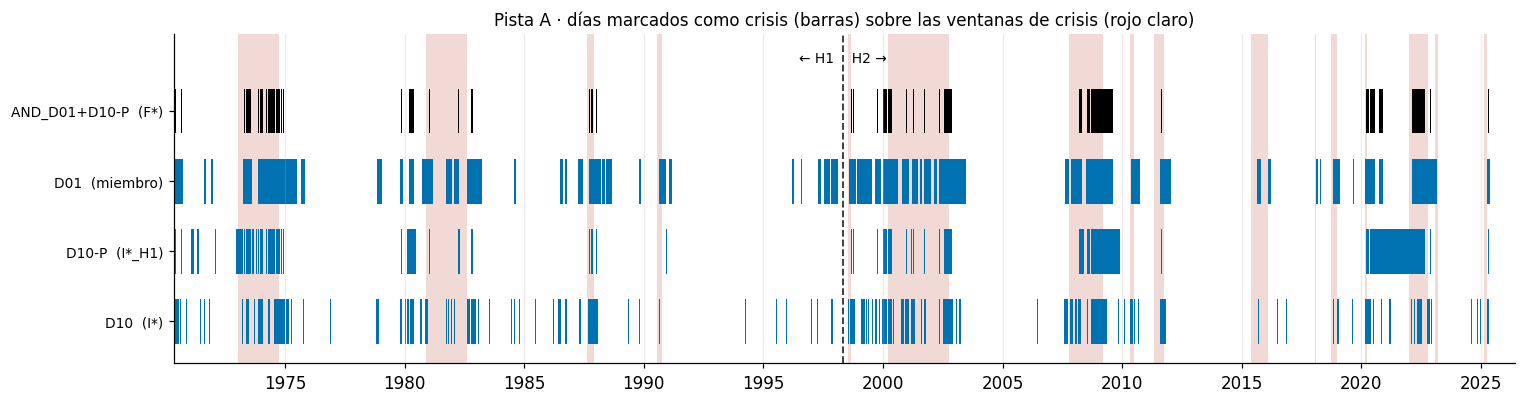

,AND_D01+D10-P,D01,D10-P,D10,días OOS
bear 1969 70,1.00,1.00,1.00,1.00,11
oil stagflation 1973,0.53,0.74,0.71,0.46,437
volcker 1980 82,0.04,0.41,0.06,0.31,431
black monday 1987,0.36,0.74,0.36,0.74,72
gulf war sl 1990,0.00,0.59,0.00,0.30,63
ltcm russia 1998,0.03,0.62,0.03,0.72,32
dotcom 2000 02,0.30,0.78,0.32,0.54,638
gfc 2007 09,0.53,0.81,0.60,0.67,356
flash crash euro1 2010,0.10,0.78,0.10,0.62,50
us downgrade euro2 2011,0.18,0.39,0.18,0.37,109


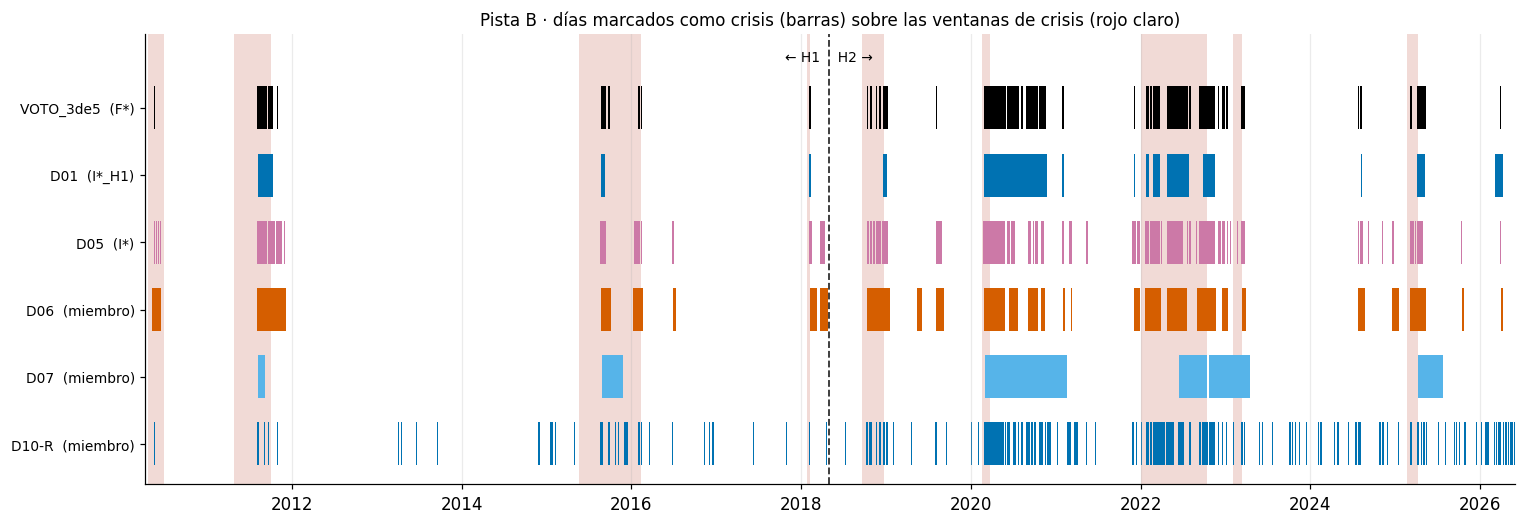

,VOTO_3de5,D01,D05,D06,D07,D10-R,días OOS
flash crash euro1 2010,0.06,0.00,0.34,0.56,0.00,0.08,50
us downgrade euro2 2011,0.35,0.37,0.36,0.38,0.17,0.15,109
china oil 2015 16,0.15,0.07,0.21,0.31,0.35,0.24,184
volmageddon 2018q1,0.40,0.40,0.50,0.30,0.00,0.50,10
fed tightening 2018q4,0.38,0.03,0.70,0.77,0.00,0.42,66
covid 2020,0.83,0.75,0.88,0.83,0.62,0.83,24
inflation bear 2022,0.71,0.56,0.73,0.70,0.42,0.67,196
svb banking 2023,0.07,0.00,0.19,0.04,1.00,0.22,27
tariff selloff 2025,0.26,0.11,0.60,0.71,0.00,0.26,35


In [21]:
for p in ff.PISTAS:
    fig = ff.figura_cronograma(CRIT, ELEC, p)
    plt.show()
    display(ff.cobertura_por_crisis(CRIT, ELEC, p).round(2))

## 8. Conclusiones y paso al notebook 16

In [22]:
A, B = HECHOS['pistas']['A'], HECHOS['pistas']['B']
display(Markdown(f'''
- **Resultado formal:** «{HECHOS['veredicto']}». En A, F\* = `{A['f_star']}` ({ff.num(A['score_f_star_oos'])}) no
  llega a {A['i_star']} ({ff.num(A['score_i_star_oos'])}) y queda {'dentro' if A['f_star_en_mcs'] else 'fuera'} del
  MCS-F; en B, F\* = `{B['f_star']}` ({ff.num(B['score_f_star_oos'])}) no llega a {B['i_star']}
  ({ff.num(B['score_i_star_oos'])}) y queda {'dentro' if B['f_star_en_mcs'] else 'fuera'} del MCS-F. Estar dentro
  del MCS quiere decir «indistinguible del mejor», no «mejor».
- **El problema es elegir, no combinar.** Existen fusiones que superan al mejor detector con todo el OOS
  ({A['n_superan_i_star']} en A, {B['n_superan_i_star']} en B, sobre todo AND con un buen detector), pero el orden
  de H1 predice mal el de H2 (Spearman {ff.num(A['rho_h1_h2'], 2)} y {ff.num(B['rho_h1_h2'], 2)}) y elegirlas a
  posteriori infla el score en {ff.num(A['optimismo'])} (A) y {ff.num(B['optimismo'])} (B).
- **Los antecedentes no se sostienen con la vara nueva.** D2+D6 queda en el puesto
  {ANT_VARA.query("pista == 'A' and pareja == 'D2+D6'")['puesto'].iloc[0]} en A y
  {ANT_VARA.query("pista == 'B' and pareja == 'D2+D6'")['puesto'].iloc[0]} en B, por debajo del mejor detector solo.
  En la familia (a), la vigilancia tras cada aviso añade sobre todo días marcados: sube el recall a costa de precisión.
- **Para la decisión final (notebook 21):** una regla fija no tiene a su favor la evidencia formal; el mejor detector
  solo sigue siendo la referencia.
'''))


- **Resultado formal:** «no aporta: combinar no mejora al mejor detector solo». En A, F\* = `AND_D01+D10-P` (0,597) no
  llega a D10 (0,614) y queda fuera del
  MCS-F; en B, F\* = `VOTO_3de5` (0,614) no llega a D05
  (0,647) y queda dentro del MCS-F. Estar dentro
  del MCS quiere decir «indistinguible del mejor», no «mejor».
- **El problema es elegir, no combinar.** Existen fusiones que superan al mejor detector con todo el OOS
  (21 en A, 2 en B, sobre todo AND con un buen detector), pero el orden
  de H1 predice mal el de H2 (Spearman 0,36 y 0,45) y elegirlas a
  posteriori infla el score en 0,045 (A) y 0,043 (B).
- **Los antecedentes no se sostienen con la vara nueva.** D2+D6 queda en el puesto
  136 de 423 en A y
  41 de 547 en B, por debajo del mejor detector solo.
  En la familia (a), la vigilancia tras cada aviso añade sobre todo días marcados: sube el recall a costa de precisión.
- **Para la decisión final (notebook 22):** una regla fija no tiene a su favor la evidencia formal; el mejor detector
  solo sigue siendo la referencia.


**Qué pasa al notebook 16 (fusión online, ADR-011 §4 y §6.2).** La online no elige detectores: pondera **todos**
los candidatos con pesos que se actualizan cada mes según el acierto pasado, así que no tiene el problema de
selección que aquí tumba a F\*. Se compara con:

- **F\*** de este notebook (`AND_D01+D10-P` en A, `VOTO_3de5` en B), leída de `results/fusion/fijas/senales_{A,B}.parquet`;
- **V** = `VOTO_mayoria` (sin selección), que es también la online con η = 0 y entrada binaria;
- **M** (media simple) e **I\*** (D10 en A, D05 en B), con el mismo criterio (i), (ii) y (iii).